# 4. Infinite DMRG

**Goal.** Get the ground state of the *infinite* TFIM chain directly, as a translation-invariant MPS, and use it to measure the energy density, the correlation length and the central charge.

*Further reading:* I. P. McCulloch, [arXiv:0804.2509](https://arxiv.org/abs/0804.2509) (iDMRG with wavefunction prediction); L. Tagliacozzo et al., [arXiv:0801.2970](https://arxiv.org/abs/0801.2970) and F. Pollmann et al., [arXiv:0812.2903](https://arxiv.org/abs/0812.2903) (finite-entanglement scaling).

In [1]:
import inspect
import time

import matplotlib.pyplot as plt
import numpy as np

import dmrg
from dmrg import infinite

## Intuition: grow the chain from the middle

White's original DMRG built long chains like this: start with two sites, and at each step insert two new sites in the middle,

$$\boxed{L}\,\bullet\bullet\,\boxed{R} \;\to\; \boxed{L\,\bullet}\,\bullet\bullet\,\boxed{\bullet\,R} \;\to\; \cdots$$

At each step, solve the two-site problem $H_\text{eff}\theta = E\theta$ exactly as in finite DMRG, split $\theta = A\,S\,B$ with a truncated SVD, absorb $A$ into the left environment and $B$ into the right one. The chain grows by two sites per step. Far from the edges the centre stops changing, and $A$, $B$, $S$ then describe the infinite chain.

* **Energy per site.** The total energy $E_N$ includes edge contributions, but they are the same at every step once converged, so $e = (E_{N+2} - E_N)/2$.
* **No sweeps.** We only ever touch the centre; the environments are the memory.

The whole algorithm, with the same building blocks as notebook 3:

In [2]:
print(inspect.getsource(infinite.idmrg))

def idmrg(W, chi_max, n_steps=200, cutoff=1e-12, predict=True, seed=0, verbose=False):
    """Run iDMRG with bulk MPO tensor ``W`` (left boundary state 0, right boundary state last).

    Returns a dict with the energy per site ``energy`` (last step), the
    history ``energies`` and ``entropies`` (centre-bond entropy), the last
    Schmidt values ``S`` and ``S_prev``, and the unit-cell tensors ``A`` and ``B``.
    """
    rng = np.random.default_rng(seed)
    D = W.shape[0]
    d = W.shape[2]
    L = np.zeros((1, D, 1))
    L[0, 0, 0] = 1.0  # start in MPO state 0
    R = np.zeros((1, D, 1))
    R[0, D - 1, 0] = 1.0  # end in the last MPO state

    E_old = 0.0
    S_prev = S_last = np.ones(1)  # Schmidt values of the previous and current centre
    A = B = None  # left and right tensors of the last step
    energies, entropies = [], []
    for step in range(n_steps):
        chi = L.shape[0]
        if predict and step >= 2:
            # theta0[a, s1, s2, e] = S[a] B[a, s1, c] / S_p

## Gapped phase first

At $h = 1.5$ the correlation length is short, and a few dozen steps give the energy density to machine precision:

e = -1.67192622153622, exact = -1.67192622153619


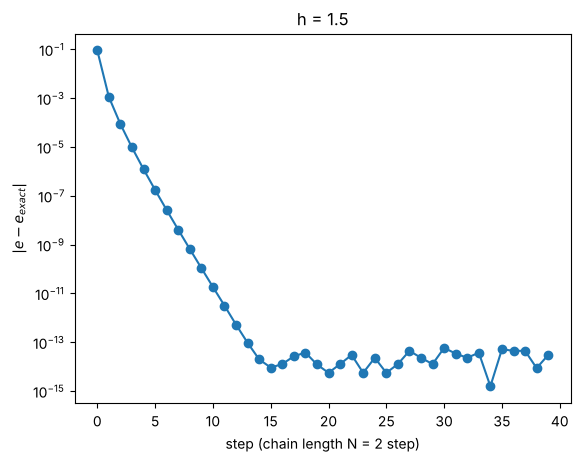

In [3]:
h = 1.5
res = dmrg.idmrg(dmrg.tfim_bulk_tensor(h), chi_max=16, n_steps=40)
e_exact = dmrg.tfim_infinite_energy_density(h)
plt.semilogy(np.abs(res["energies"] - e_exact), "o-")
plt.xlabel("step (chain length N = 2 step)")
plt.ylabel("$|e - e_{exact}|$")
plt.title(f"h = {h}")
print(f"e = {res['energy']:.14f}, exact = {e_exact:.14f}")

## McCulloch's wavefunction prediction

Each step starts Lanczos from some vector. A random one works but wastes iterations. McCulloch noticed that the new centre looks like the old one shifted by one site, and in terms of the last step's tensors that shifted state is

$$\theta_\text{guess} = S\,B\,S_\text{prev}^{-1}\,A\,S.$$

It costs one line and is several times faster near criticality:

In [4]:
for predict in [False, True]:
    t = time.perf_counter()
    r = dmrg.idmrg(dmrg.tfim_bulk_tensor(1.0), chi_max=16, n_steps=300, predict=predict)
    print(f"predict = {predict!s:5}: {time.perf_counter() - t:5.1f} s, e = {r['energy']:.10f}")

predict = False:  12.4 s, e = -1.2732388328


predict = True :   3.3 s, e = -1.2732388327


## The critical point

At $h = 1$ the true correlation length is infinite, but an MPS with finite $\chi$ always has a finite one: $\chi$ acts like a system size. Read the correlation length from the **transfer matrix** of the unit cell: its leading eigenvalue is 1, and the next one gives $\xi = -2/\log|\lambda_2|$ (two sites per cell). The theory of finite-entanglement scaling then says

$$\xi \propto \chi^{\kappa}, \qquad S = \frac{c}{6}\log\xi + \text{const},$$

with $\kappa = 6/\big(c(\sqrt{12/c}+1)\big) \approx 2.03$ for $c = 1/2$ (Pollmann et al.). Note that the iDMRG chain must grow well beyond $\xi$ before it converges, so we take 1000 steps (2000 sites).

chi =  6: e - e_exact = 3.0e-05, S = 0.5875, xi =   54.7


chi =  8: e - e_exact = 1.7e-05, S = 0.6151, xi =   77.0


chi = 10: e - e_exact = 3.6e-06, S = 0.6865, xi =  175.2


chi = 12: e - e_exact = 2.0e-06, S = 0.7146, xi =  238.9


chi = 16: e - e_exact = 5.8e-07, S = 0.7618, xi =  434.2


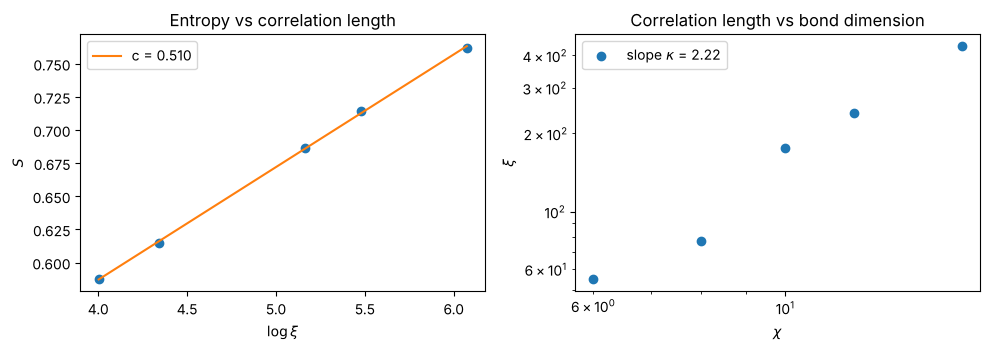

In [5]:
chis = [6, 8, 10, 12, 16]
S, xi, de = [], [], []
for chi in chis:
    r = dmrg.idmrg(dmrg.tfim_bulk_tensor(1.0), chi_max=chi, n_steps=1000)
    S.append(r["entropies"][-1])
    xi.append(dmrg.correlation_length(r))
    de.append(r["energy"] - dmrg.tfim_infinite_energy_density(1.0))
    print(f"chi = {chi:2d}: e - e_exact = {de[-1]:.1e}, S = {S[-1]:.4f}, xi = {xi[-1]:6.1f}")

c = 6 * np.polyfit(np.log(xi), S, 1)[0]
kappa = np.polyfit(np.log(chis), np.log(xi), 1)[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(np.log(xi), S, "o")
ax[0].plot(np.log(xi), c / 6 * np.log(xi) + np.polyfit(np.log(xi), S, 1)[1], "-", label=f"c = {c:.3f}")
ax[0].set(xlabel=r"$\log\xi$", ylabel="$S$", title="Entropy vs correlation length")
ax[0].legend()
ax[1].loglog(chis, xi, "o", label=f"slope $\\kappa$ = {kappa:.2f}")
ax[1].set(xlabel=r"$\chi$", ylabel=r"$\xi$", title="Correlation length vs bond dimension")
ax[1].legend()
plt.tight_layout()

We recover $c \approx 0.5$ for the Ising universality class. $\kappa$ is noisier: $\xi(\chi)$ jumps a little depending on where the Schmidt spectrum is cut, a known feature of finite-entanglement scaling.

## The ordered phase: a cat

At $h < 1$ the $\mathbb{Z}_2$ symmetry $\prod_i Z_i$ is spontaneously broken, but iDMRG with a symmetric Hamiltonian finds the symmetric superposition of the two ordered states. You can see it in the numbers: entropy close to $\log 2$, and a second transfer-matrix eigenvalue equal to 1, so "$\xi = \infty$":

In [6]:
r = dmrg.idmrg(dmrg.tfim_bulk_tensor(0.5), chi_max=16, n_steps=40)
print(f"S = {r['entropies'][-1]:.6f}, log 2 = {np.log(2):.6f}, xi = {dmrg.correlation_length(r):.1e}")

S = 0.696067, log 2 = 0.693147, xi = 5.3e+09


## Comparison with TeNPy

`benchmarks/benchmark_tenpy.py` runs the same problems with [TeNPy](https://github.com/tenpy/tenpy) ([arXiv:1805.00055](https://arxiv.org/abs/1805.00055)). On one CPU core, at $h = 1$:

| | ours | TeNPy |
|---|---|---|
| finite, $L = 100$, $\chi = 32$, 4 sweeps: energy error | $8.6\times10^{-11}$ | $8.3\times10^{-11}$ |
| time | 17 s | 11 s |
| finite, $L = 100$, $\chi = 64$: time | 53 s | 16 s |
| infinite, $\chi = 16$: $e - e_\text{exact}$ | $5.8\times10^{-7}$ | $5.8\times10^{-7}$ |
| $S$, $\xi$ | 0.763, 439 | 0.762, 433 |
| time | 10 s | 12 s |

Same accuracy. TeNPy is about 3× faster at large $\chi$ thanks to BLAS-backed contractions, but our iDMRG holds its own.

## Exercises

1. Plot the iDMRG energy density against $h$ from 0 to 2 and overlay the exact curve. Where is the error largest, and why?
2. Add a tiny symmetry-breaking field $-\epsilon\sum_i X_i$ at $h = 0.5$. What happens to $S$ and $\xi$? Measure the magnetization $\langle X\rangle$ and compare with the exact $(1-h^2)^{1/8}$.
3. Replace the growing algorithm by sweeping iDMRG on a two-site unit cell (TeNPy's approach): keep $L$ and $R$, but re-optimize the same unit cell repeatedly. Does it converge faster at $h = 1$?